# Fixed replay over the full BDD100K stream

**Complete** · queue · ETA 0h 00m 00s 

Updated 19:26:14 Västeuropa, normaltid · 15.93 GiB free

Both arms use one AdamW update at 0.000075 and two independently masked gradient images per arrival. Replay replaces the second current view with a frame aged 256–2,048 arrivals. The primary endpoint uses 10,000 newly reserved frames disjoint from the original train, validation, and test clips. Training curves record pre-update incoming loss each step and rolling-bank metrics every 128 steps.

| Seed | Arm | State | Updates | Gradient images | Training time |
| --- | --- | --- | --- | --- | --- |
 | 2026 | Two current views | complete | 72,000/72,000 | 144,000 | 0h 12m 30s | 
 | 2026 | Current + older replay | complete | 72,000/72,000 | 144,000 | 0h 12m 28s | 
 | 2027 | Two current views | complete | 72,000/72,000 | 144,000 | 0h 12m 39s | 
 | 2027 | Current + older replay | complete | 72,000/72,000 | 144,000 | 0h 13m 10s | 
 | 2028 | Two current views | complete | 72,000/72,000 | 144,000 | 0h 12m 43s | 
 | 2028 | Current + older replay | complete | 72,000/72,000 | 144,000 | 0h 12m 36s | 



## Reconstruction loss and RankMe during training

Each point averages up to 1,000 checkpointed pre-action measurements. Loss is masked-patch MSE. RankMe is measured on unmasked encoder embeddings from the rolling bank. The vertical line at 8,000 images marks the shared calibration checkpoint for each seed.

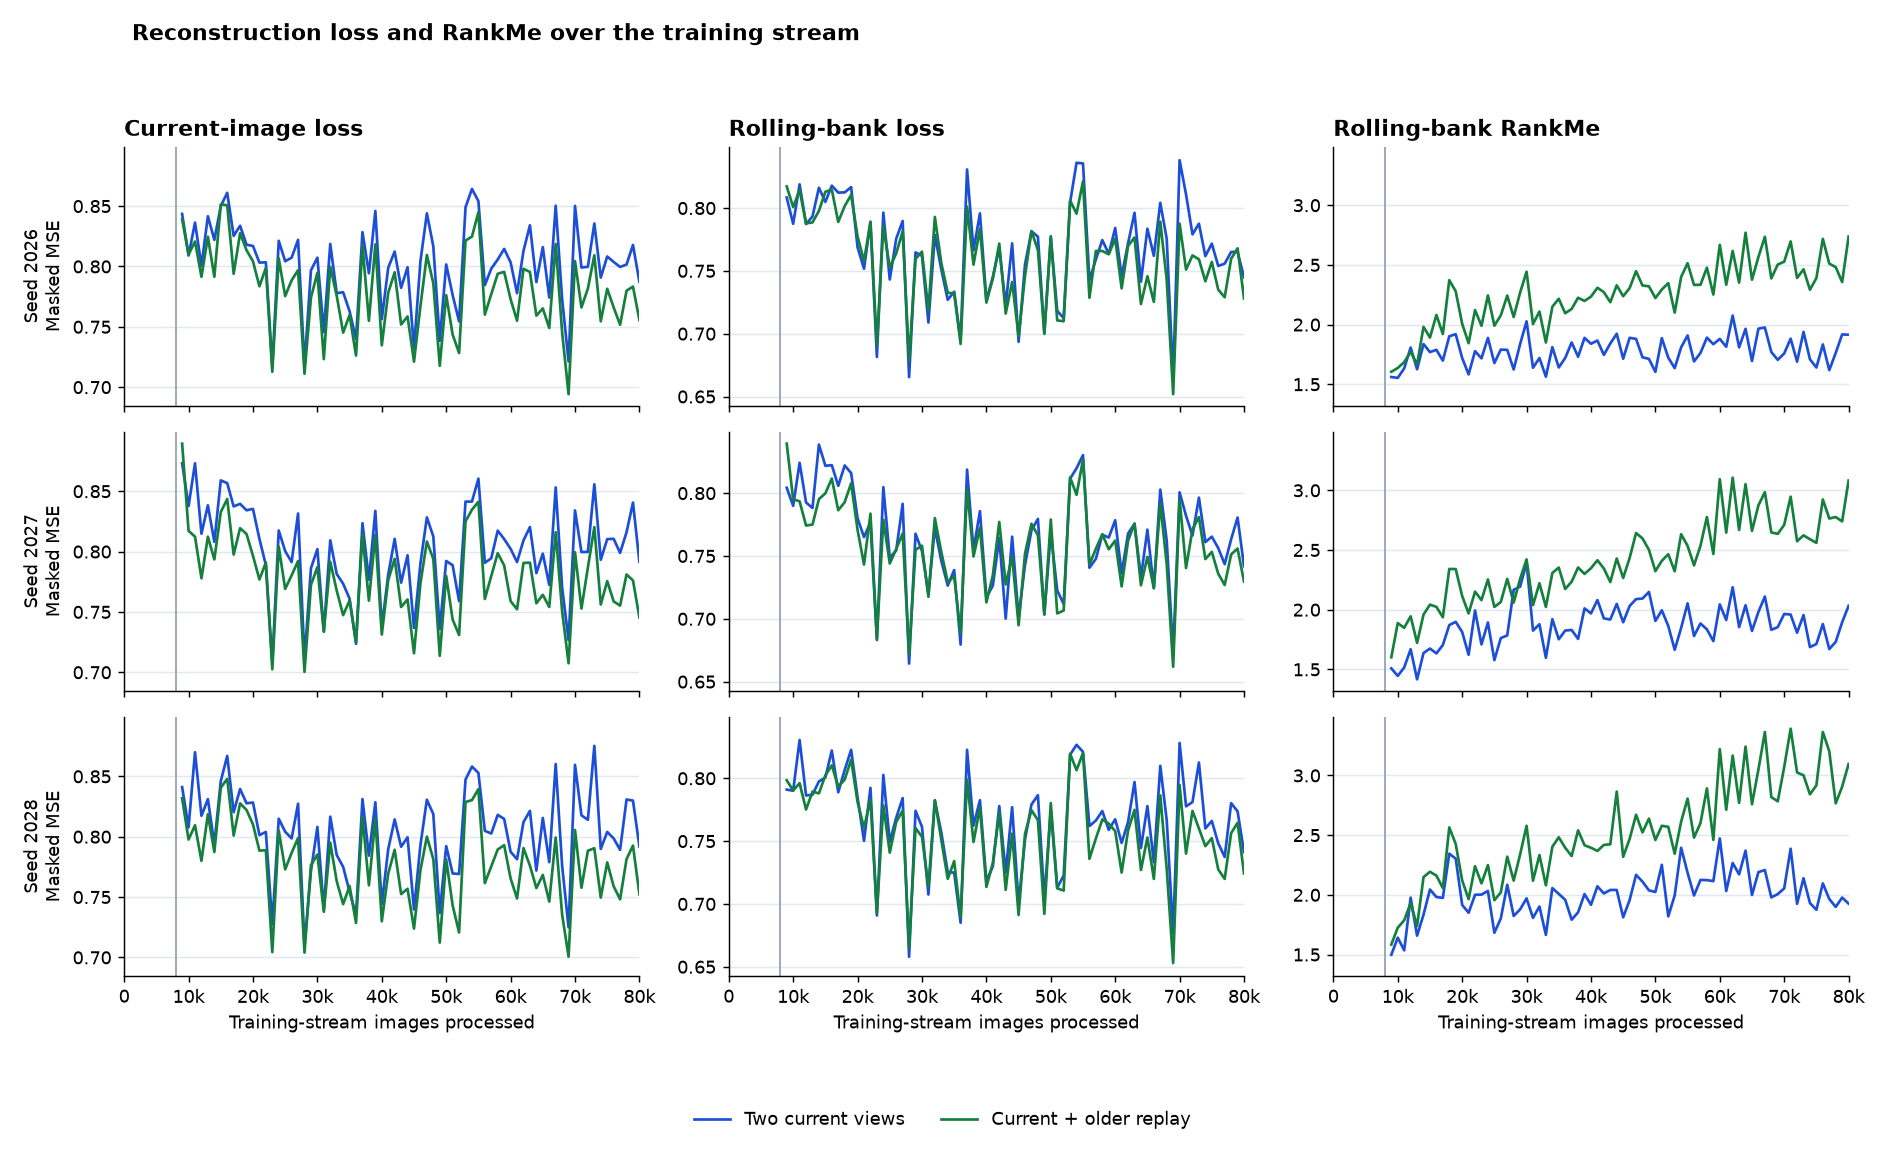

Run the watcher cell at the bottom for live plots while this notebook is open.

## Validation and held-out outcomes

Mean confirmation MSE across 3 paired seeds is 0.914511 for current-only and 0.845742 for replay. Replay minus current is **-0.068769**, with a 95% clip-bootstrap interval of [-0.086363, -0.052294].

| Seed | Arm | Confirmation MSE | Confirmation RankMe | Original test MSE | Older-frame MSE | Older-frame change | Training time |
| --- | --- | --- | --- | --- | --- | --- | --- |
 | 2026 | Two current views | 0.896380 | 3.2319 | 0.876799 | 0.856793 | -0.150570 | 0h 12m 30s | 
 | 2026 | Current + older replay | 0.844540 | 5.2563 | 0.837033 | 0.814875 | -0.192487 | 0h 12m 28s | 
 | 2027 | Two current views | 0.923645 | 3.5358 | 0.908270 | 0.892916 | -0.205683 | 0h 12m 39s | 
 | 2027 | Current + older replay | 0.850796 | 6.6815 | 0.848356 | 0.819860 | -0.278740 | 0h 13m 10s | 
 | 2028 | Two current views | 0.923508 | 3.3241 | 0.906584 | 0.890353 | -0.173374 | 0h 12m 43s | 
 | 2028 | Current + older replay | 0.841889 | 6.8385 | 0.837259 | 0.816952 | -0.246774 | 0h 12m 36s | 

In [ ]:
# Run this cell to watch the training curves. Interrupt it to stop watching.
from IPython.display import Image, clear_output, display
from pathlib import Path
import json, time

chart_path = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\full-stream-replay\\training-curves.png')
status_path = chart_path.with_name('status.json')
while True:
    try:
        status = json.loads(status_path.read_text(encoding='utf-8'))
        png = chart_path.read_bytes()
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    display(Image(data=png))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)
